In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

### EDA and Data Preparation

--- DATASET SUMMARY ---
Total samples: 569, Features: 30
Missing values count: 0
Class distribution:
target
1    357
0    212
Name: count, dtype: int64

--- STATISTICAL OVERVIEW (First 5 Features) ---
       radius_mean  texture_mean  perimeter_mean    area_mean  smoothness_mean
count   569.000000    569.000000      569.000000   569.000000       569.000000
mean     14.127292     19.289649       91.969033   654.889104         0.096360
std       3.524049      4.301036       24.298981   351.914129         0.014064
min       6.981000      9.710000       43.790000   143.500000         0.052630
25%      11.700000     16.170000       75.170000   420.300000         0.086370
50%      13.370000     18.840000       86.240000   551.100000         0.095870
75%      15.780000     21.800000      104.100000   782.700000         0.105300
max      28.110000     39.280000      188.500000  2501.000000         0.163400


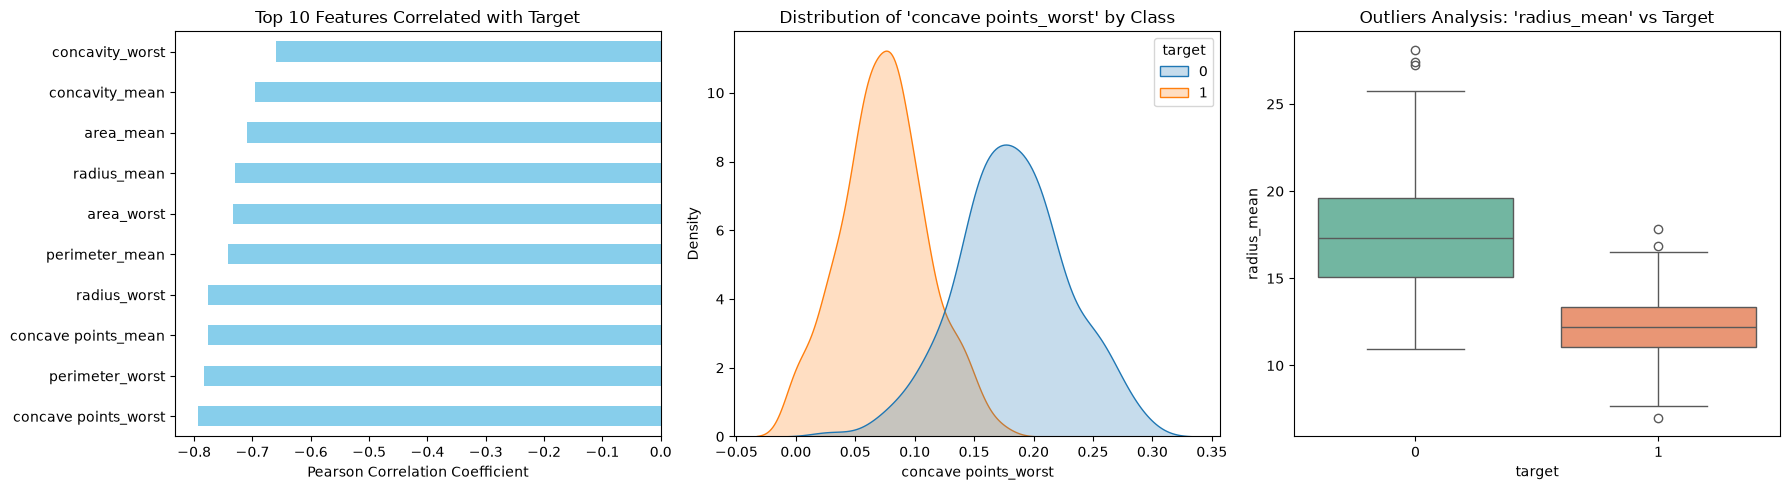

In [9]:
# Dataset: Breast Cancer Wisconsin (Diagnostic) from CSV file
# Kaggle Link: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

# Load dataset directly from CSV file
df = pd.read_csv("data/data.csv")

# Drop unnecessary columns if they exist in the Kaggle CSV ('id', 'Unnamed: 32')
cols_to_drop = [col for col in ['id', 'Unnamed: 32'] if col in df.columns]
if cols_to_drop:
    df = df.drop(columns=cols_to_drop)

# Convert string target 'diagnosis' ('M'/'B') to numeric 'target' (0/1) if needed
# M = Malignant (0), B = Benign (1)
if 'diagnosis' in df.columns:
    df['target'] = df['diagnosis'].map({'M': 0, 'B': 1})
    df = df.drop(columns=['diagnosis'])

# Find exact column names for visualization (handles both 'worst concave points' and 'concave points_worst')
concave_pts_col = next((c for c in df.columns if 'concave' in c and 'worst' in c), None)
mean_radius_col = next((c for c in df.columns if 'radius' in c and 'mean' in c), None)

print("--- DATASET SUMMARY ---")
print(f"Total samples: {df.shape[0]}, Features: {df.shape[1] - 1}")
print(f"Missing values count: {df.isnull().sum().sum()}")
print(f"Class distribution:\n{df['target'].value_counts()}\n")

# Statistical overview of the first 5 features
print("--- STATISTICAL OVERVIEW (First 5 Features) ---")
print(df.iloc[:, :5].describe())

# Compute correlation of all features with the target variable
correlations = df.corr()['target'].drop('target').sort_values()

# Visualizations: Correlations, Density plot, and Outliers Analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Top 10 negative correlations with target
top_corr = correlations.head(10)
top_corr.plot(kind='barh', ax=axes[0], color='skyblue')
axes[0].set_title("Top 10 Features Correlated with Target")
axes[0].set_xlabel("Pearson Correlation Coefficient")

# Plot 2: Distribution of key feature by target class
if concave_pts_col:
    sns.kdeplot(data=df, x=concave_pts_col, hue='target', common_norm=False, ax=axes[1], fill=True)
    axes[1].set_title(f"Distribution of '{concave_pts_col}' by Class")

# Plot 3: Boxplot for outlier detection in key feature
if mean_radius_col:
    sns.boxplot(x='target', y=mean_radius_col, hue='target', data=df, ax=axes[2], palette='Set2', legend=False)
    axes[2].set_title(f"Outliers Analysis: '{mean_radius_col}' vs Target")

plt.tight_layout()
plt.show()

# Separate feature matrix X and target vector y
X = df.drop(columns=['target']).values
y = df['target'].values

# Split dataset into training (80%) and testing (20%) sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=None, stratify=y
)

# Standardize features (Mean = 0, Standard Deviation = 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Custom MLP

In [10]:
class CustomMLP:
    """
    A 2-layer Multi-Layer Perceptron (1 Hidden Layer, 1 Output Layer)
    implemented from scratch using NumPy with Backpropagation and SGD.
    """
    def __init__(self, input_dim, hidden_dim, output_dim=1, learning_rate=0.05, epochs=1000):
        self.lr = learning_rate
        self.epochs = epochs
        
        # Initialize weights using He / Xavier initialization method
        np.random.seed(42)
        self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2.0 / hidden_dim)
        self.b2 = np.zeros((1, output_dim))
        
        self.loss_history = []

    def _sigmoid(self, z):
        """Sigmoid activation function with numerical stability clipping."""
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def _relu(self, z):
        """ReLU activation function for the hidden layer."""
        return np.maximum(0, z)

    def _relu_derivative(self, z):
        """Derivative of ReLU activation function."""
        return (z > 0).astype(float)

    def forward(self, X):
        """
        Forward propagation through the network:
        Input (30) -> Hidden (16, ReLU) -> Output (1, Sigmoid)
        """
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = self._relu(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = self._sigmoid(self.z2)
        return self.a2

    def fit(self, X, y):
        """
        Train the MLP classifier using Backpropagation algorithm.
        """
        m = X.shape[0]
        y_reshaped = y.reshape(-1, 1)

        for epoch in range(self.epochs):
            # Forward pass
            a2 = self.forward(X)

            # Compute Binary Cross-Entropy Loss
            loss = -np.mean(
                y_reshaped * np.log(a2 + 1e-15) + (1 - y_reshaped) * np.log(1 - a2 + 1e-15)
            )
            self.loss_history.append(loss)

            # Backpropagation: Output Layer Gradients
            dz2 = a2 - y_reshaped
            dW2 = (1 / m) * np.dot(self.a1.T, dz2)
            db2 = (1 / m) * np.sum(dz2, axis=0, keepdims=True)

            # Backpropagation: Hidden Layer Gradients
            da1 = np.dot(dz2, self.W2.T)
            dz1 = da1 * self._relu_derivative(self.z1)
            dW1 = (1 / m) * np.dot(X.T, dz1)
            db1 = (1 / m) * np.sum(dz1, axis=0, keepdims=True)

            # Gradient Descent Weight Updates
            self.W2 -= self.lr * dW2
            self.b2 -= self.lr * db2
            self.W1 -= self.lr * dW1
            self.b1 -= self.lr * db1

    def predict_proba(self, X):
        """Predict class probabilities."""
        return self.forward(X)

    def predict(self, X, threshold=0.5):
        """Predict binary labels (0 or 1)."""
        proba = self.predict_proba(X)
        return (proba >= threshold).astype(int).flatten()


# Instantiate and train the custom model
custom_mlp = CustomMLP(
    input_dim=X.shape[1],
    hidden_dim=16,
    learning_rate=0.05,
    epochs=1000
)
custom_mlp.fit(X_train_scaled, y_train)

# Evaluate model on test set
y_pred_custom = custom_mlp.predict(X_test_scaled)

### Referance model: Scikit-Learn MLPClassifier

In [11]:
sk_mlp = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=None
)
sk_mlp.fit(X_train_scaled, y_train)

# Evaluate scikit-learn model
y_pred_sk = sk_mlp.predict(X_test_scaled)

### Metrics & Perfomance Comparison

In [14]:
def display_metrics(model_name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    print(f"=== {model_name} Metrics ===")
    print(f"Accuracy : {acc * 100:.2f}%")
    print(f"Precision: {prec * 100:.2f}%")
    print(f"Recall   : {rec * 100:.2f}%")
    print(f"F1-Score : {f1 * 100:.2f}%\n")

display_metrics("Custom MLP (NumPy)", y_test, y_pred_custom)
display_metrics("Scikit-Learn MLPClassifier", y_test, y_pred_sk)

=== Custom MLP (NumPy) Metrics ===
Accuracy : 95.61%
Precision: 95.89%
Recall   : 97.22%
F1-Score : 96.55%

=== Scikit-Learn MLPClassifier Metrics ===
Accuracy : 96.49%
Precision: 95.95%
Recall   : 98.61%
F1-Score : 97.26%



### Visualization of Results

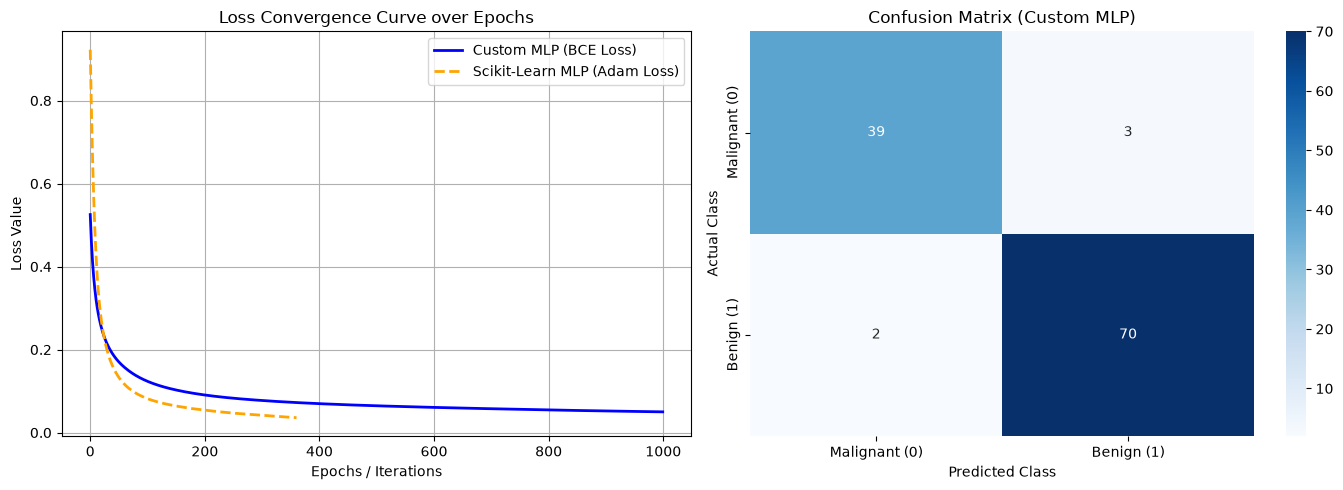

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot loss convergence curves
axes[0].plot(custom_mlp.loss_history, label='Custom MLP (BCE Loss)', color='blue', linewidth=2)
axes[0].plot(sk_mlp.loss_curve_, label='Scikit-Learn MLP (Adam Loss)', color='orange', linestyle='--', linewidth=2)
axes[0].set_title("Loss Convergence Curve over Epochs")
axes[0].set_xlabel("Epochs / Iterations")
axes[0].set_ylabel("Loss Value")
axes[0].grid(True)
axes[0].legend()

# Plot confusion matrix
cm_custom = confusion_matrix(y_test, y_pred_custom)
sns.heatmap(
    cm_custom, annot=True, fmt='d', cmap='Blues', ax=axes[1],
    xticklabels=['Malignant (0)', 'Benign (1)'],
    yticklabels=['Malignant (0)', 'Benign (1)']
)
axes[1].set_title("Confusion Matrix (Custom MLP)")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

plt.tight_layout()
plt.show()